# Why the score moved from about 0.54 to about 0.70

The first benchmark labeled every censored patient as a negative. Many of those patients simply were not followed long enough to record progression, so the models had little to rank. This notebook keeps the same graphs and the same rule that follow-up time is not a feature. It changes the question to: **did progression happen by 36 months?**

Patients censored before 36 months are left out. A progression after 36 months counts as event-free at the horizon. The cohort is 498 patients, 89 of whom progressed by 36 months.

## What changed in the model

- A logistic regression on age, sex, subtype, stage, and M stage is the baseline. It does not see gene alterations or PrimeKG.
- The MLP and the graph networks add that same clinical score through a linear head. The graph or alteration score is gated and starts near zero, so training begins from the clinical score.
- Mean and max pooling use the patient node and the altered genes. Unaltered pathway neighbors still carry messages, and they are not averaged into the readout.
- `PFS_MONTHS` is used only to decide who is inside the 36-month window.

## Result

| Model | AUROC | AUPRC |
| --- | --- | --- |
| Clinical logistic regression | 0.703 ± 0.081 | 0.463 ± 0.133 |
| GCN | 0.680 ± 0.076 | 0.396 ± 0.091 |
| GraphSAGE | 0.650 ± 0.045 | 0.379 ± 0.091 |
| GATv2 | 0.631 ± 0.046 | 0.355 ± 0.060 |
| MLP | 0.562 ± 0.098 | 0.262 ± 0.064 |

Chance for AUROC is 0.50. Chance for AUPRC is the positive rate, 0.179. The earlier raw-PFS GraphSAGE result was AUROC 0.542 and AUPRC 0.216.

The clinical model is the best ranking. GCN is close and does not beat subtype and stage. PrimeKG is still available for the path explanations, and it is not what raised the AUROC.

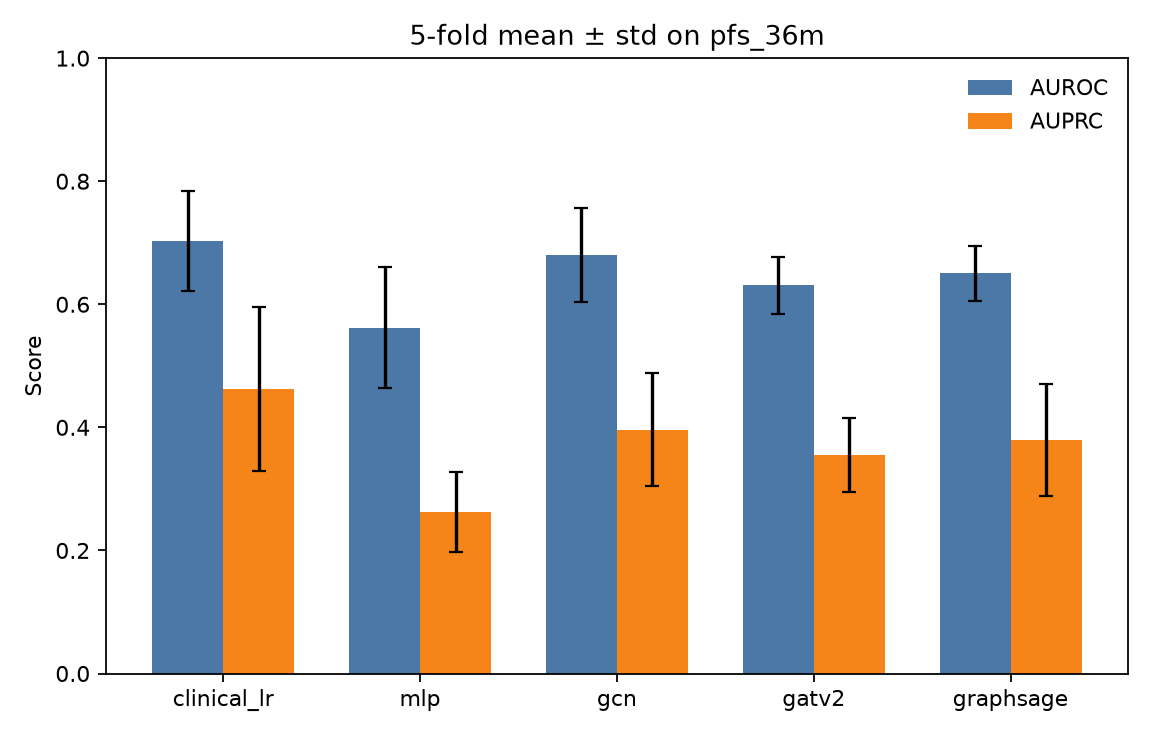

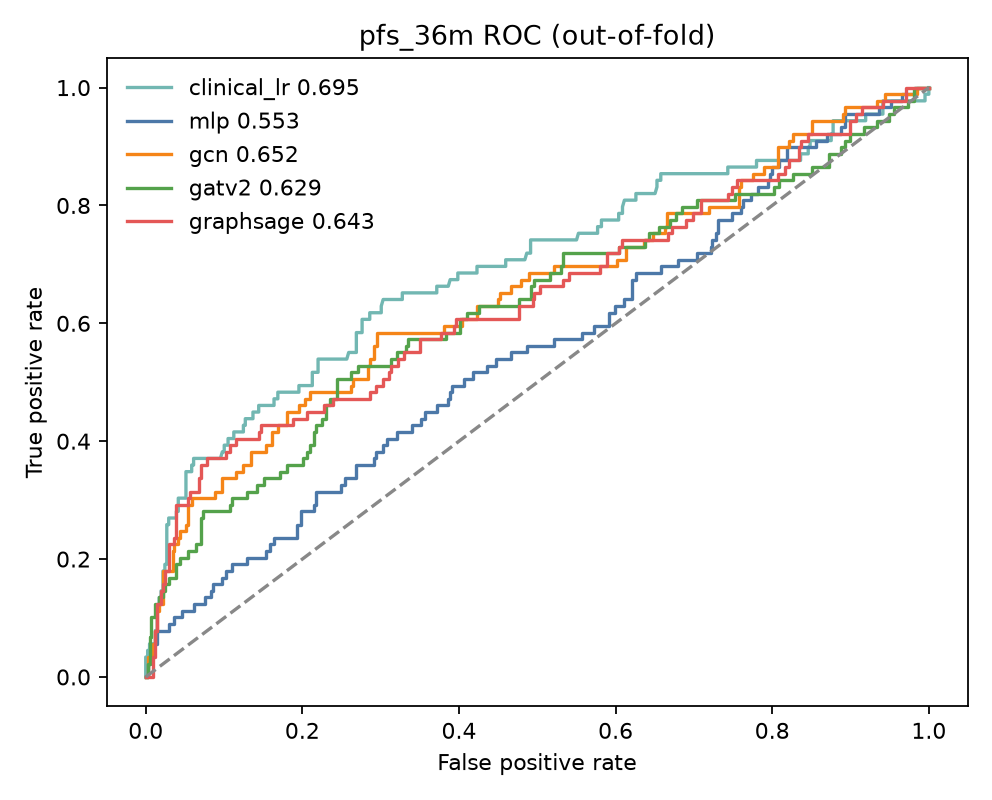

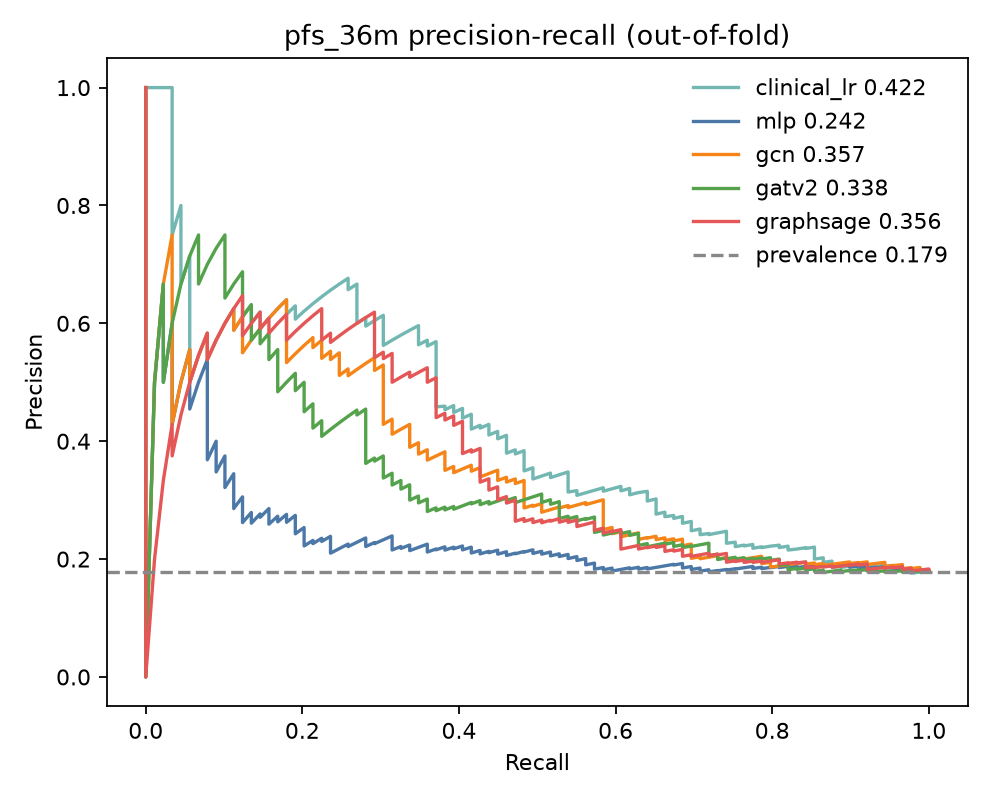

In [1]:
from IPython.display import Image, display
display(Image('outputs/gnn_benchmark_36m/comparison_bars.png'))
display(Image('outputs/gnn_benchmark_36m/roc_curves.png'))
display(Image('outputs/gnn_benchmark_36m/pr_curves.png'))


## How to read this for a mentor

The first number near 0.5 was mostly a label problem, plus a network that buried the clinical fields under a 1,500-gene vector and a few hundred shared pathway nodes. Asking a 36-month question and fitting those clinical fields directly gets AUROC about 0.70. That is a usable ranking signal for a research discussion. It is not a clinical test: each fold has about 18 events, and one clinical fold is 0.57 while another is 0.78.

An example GCN path, using only edges stored in the fused graph, is TCGA-AC-A2FE → sample → amplified SHANK2 → pathway Neurexins and neuroligins. Paths like that explain a prediction. They are not evidence that the graph outperformed stage and subtype.